# Task 1: Exploratory Data Analysis on Superstore Retail Sales

**Program:** Datheon Data Analytics & Power BI Internship
**Dataset:** Superstore Sales (US orders, Jan 2015 to Dec 2018)
**Tools:** Python, Pandas, Matplotlib, Seaborn

**Goal:** Look at purchase volume, monthly seasonality, category-wise revenue and discount sensitivity, then give at least five executive takeaways.

**Steps in this notebook**
1. Load and clean the data
2. Customer purchase volume
3. Monthly seasonality
4. Category, Region and Segment performance
5. Discount sensitivity
6. Returns
7. Business findings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
pd.options.display.float_format = "{:,.2f}".format

## 1. Load and clean the data

In [2]:
raw = pd.read_csv("../data/superstore_sales.csv")
print("Rows x columns:", raw.shape)
raw.tail(10)

Rows x columns: (10800, 21)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10790,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10791,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10792,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10793,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10794,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The file has 10,800 rows, but the real orders stop at row 9,994. The rows below that are two small lookup tables pasted into the same CSV: a **People** table (regional managers) and a **Returns** table (order IDs that were returned). They are not orders, so I split them out instead of treating them as missing data.

In [3]:
# Real orders have a Sales value. The pasted lookup tables do not.
orders = raw[raw["Sales"].notna()].copy()
extra = raw[raw["Sales"].isna()]

# Returns table: rows where the first column says "Yes" and the second column is the Order ID
returns = (extra[extra["Row ID"].eq("Yes")][["Order ID"]]
           .drop_duplicates()
           .assign(Returned="Yes"))

print("Order rows            :", len(orders))
print("Lookup rows removed   :", len(extra))
print("Returned order IDs    :", len(returns))

Order rows            : 9994
Lookup rows removed   : 806
Returned order IDs    : 296

In [4]:
# Fix data types
orders["Row ID"] = orders["Row ID"].astype(int)
orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="%m/%d/%Y")
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"], format="%m/%d/%Y")
orders["Quantity"] = orders["Quantity"].astype(int)

# Postal code is missing for 11 rows. All of them are Burlington, Vermont.
missing_pc = orders[orders["Postal Code"].isna()]
print("Missing postal codes:", len(missing_pc), "| cities:", missing_pc["City"].unique(), missing_pc["State"].unique())

# Burlington, VT uses ZIP 05401. Keep postal code as text so the leading zero survives.
orders.loc[orders["Postal Code"].isna(), "Postal Code"] = 5401
orders["Postal Code"] = orders["Postal Code"].astype(int).astype(str).str.zfill(5)

Missing postal codes: 11 | cities: <StringArray>
['Burlington']
Length: 1, dtype: str <StringArray>
['Vermont']
Length: 1, dtype: str

In [5]:
# Quality checks
print("Remaining nulls          :", int(orders.isna().sum().sum()))
print("Duplicate rows           :", int(orders.duplicated().sum()))
print("Duplicate Row IDs        :", int(orders["Row ID"].duplicated().sum()))
print("Sales <= 0               :", int((orders["Sales"] <= 0).sum()))
print("Discount outside 0 to 1  :", int((~orders["Discount"].between(0, 1)).sum()))
print("Ship date before order   :", int((orders["Ship Date"] < orders["Order Date"]).sum()))
print("Loss-making rows         :", int((orders["Profit"] < 0).sum()), f"({(orders['Profit'] < 0).mean():.1%})")
print("Date range               :", orders["Order Date"].min().date(), "to", orders["Order Date"].max().date())

Remaining nulls          : 0
Duplicate rows           : 0
Duplicate Row IDs        : 0
Sales <= 0               : 0
Discount outside 0 to 1  : 0
Ship date before order   : 0
Loss-making rows         : 1871 (18.7%)
Date range               : 2015-01-03 to 2018-12-30

In [6]:
# New columns used in the analysis
orders["Year"] = orders["Order Date"].dt.year
orders["Month"] = orders["Order Date"].dt.month
orders["Year-Month"] = orders["Order Date"].dt.to_period("M")
orders["Profit Margin %"] = orders["Profit"] / orders["Sales"] * 100
orders["Ship Days"] = (orders["Ship Date"] - orders["Order Date"]).dt.days
orders = orders.merge(returns, on="Order ID", how="left")
orders["Returned"] = orders["Returned"].fillna("No")

orders[["Sales", "Quantity", "Discount", "Profit", "Profit Margin %", "Ship Days"]].describe()

,Sales,Quantity,Discount,Profit,Profit Margin %,Ship Days
count,"9,994.00","9,994.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,229.86,3.79,0.16,28.66,12.03,3.96
std,623.25,2.23,0.21,234.26,46.68,1.75
min,0.44,1.00,0.00,"-6,599.98",-275.00,0.00
25%,17.28,2.00,0.00,1.73,7.50,3.00
50%,54.49,3.00,0.20,8.67,27.00,4.00
75%,209.94,5.00,0.20,29.36,36.25,5.00
max,"22,638.48",14.00,0.80,"8,399.98",50.00,7.00


In [7]:
total_sales = orders["Sales"].sum()
total_profit = orders["Profit"].sum()
kpi = pd.Series({
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Profit Margin %": total_profit / total_sales * 100,
    "Orders": orders["Order ID"].nunique(),
    "Customers": orders["Customer ID"].nunique(),
    "Units Sold": orders["Quantity"].sum(),
    "Average Order Value": total_sales / orders["Order ID"].nunique(),
})
kpi.to_frame("Value")

,Value
Total Sales,"2,297,200.86"
Total Profit,"286,397.02"
Profit Margin %,12.47
Orders,"5,009.00"
Customers,793.00
Units Sold,"37,873.00"
Average Order Value,458.61


## 2. Customer purchase volume

Customers with 2+ orders        : 98.5%
Average orders per customer     : 6.3
Sales share of top 20% customers: 48.0%

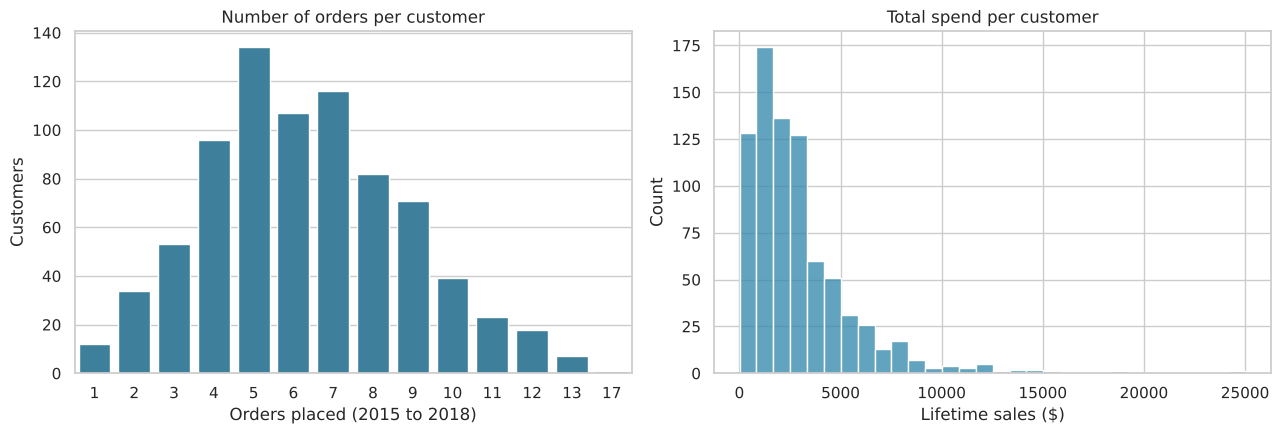

In [8]:
cust = orders.groupby("Customer ID").agg(
    orders=("Order ID", "nunique"),
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x="orders", data=cust, color="#2E86AB", ax=ax[0])
ax[0].set_title("Number of orders per customer")
ax[0].set_xlabel("Orders placed (2015 to 2018)")
ax[0].set_ylabel("Customers")

sns.histplot(cust["sales"], bins=30, color="#2E86AB", ax=ax[1])
ax[1].set_title("Total spend per customer")
ax[1].set_xlabel("Lifetime sales ($)")
plt.tight_layout()

repeat = (cust["orders"] > 1).mean()
top20 = cust["sales"].sort_values(ascending=False).head(int(len(cust) * 0.2)).sum() / cust["sales"].sum()
print(f"Customers with 2+ orders        : {repeat:.1%}")
print(f"Average orders per customer     : {cust['orders'].mean():.1f}")
print(f"Sales share of top 20% customers: {top20:.1%}")

In [9]:
top10 = (orders.groupby("Customer Name")[["Sales", "Profit"]].sum()
         .sort_values("Sales", ascending=False).head(10))
top10

,Sales,Profit
Customer Name,,
Sean Miller,"25,043.05","-1,980.74"
Tamara Chand,"19,052.22","8,981.32"
Raymond Buch,"15,117.34","6,976.10"
Tom Ashbrook,"14,595.62","4,703.79"
Adrian Barton,"14,473.57","5,444.81"
Ken Lonsdale,"14,175.23",806.86
Sanjit Chand,"14,142.33","5,757.41"
Hunter Lopez,"12,873.30","5,622.43"
Sanjit Engle,"12,209.44","2,650.68"


In [10]:
# Order volume by customer segment
seg_cust = orders.groupby("Segment").agg(
    Customers=("Customer ID", "nunique"),
    Orders=("Order ID", "nunique"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
)
seg_cust["Orders per Customer"] = seg_cust["Orders"] / seg_cust["Customers"]
seg_cust["Margin %"] = seg_cust["Profit"] / seg_cust["Sales"] * 100
seg_cust

,Customers,Orders,Sales,Profit,Orders per Customer,Margin %
Segment,,,,,,
Consumer,409,2586,"1,161,401.34","134,119.21",6.32,11.55
Corporate,236,1514,"706,146.37","91,979.13",6.42,13.03
Home Office,148,909,"429,653.15","60,298.68",6.14,14.03


## 3. Monthly seasonality

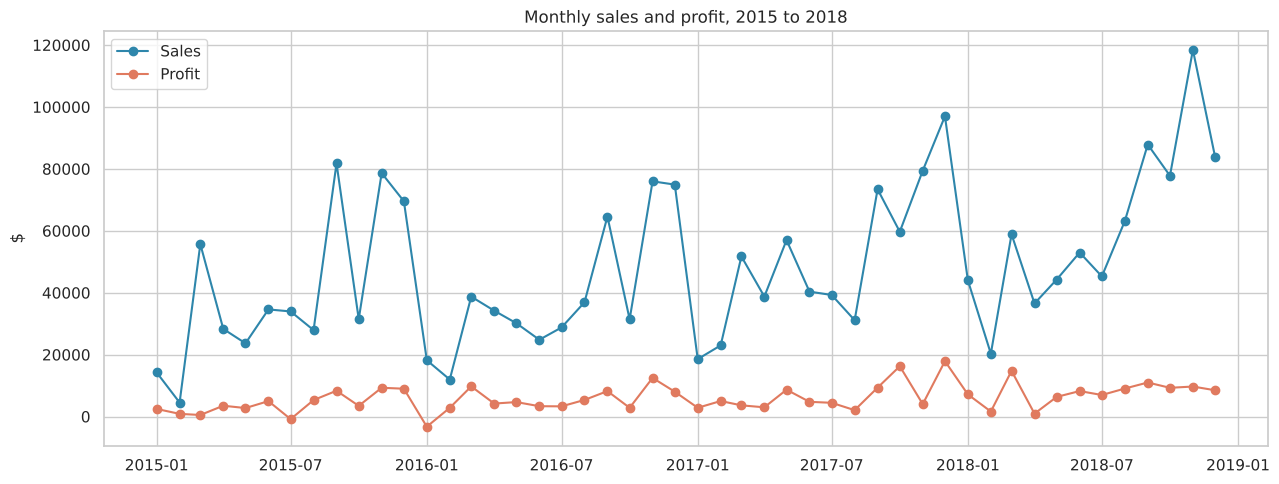

In [11]:
monthly = orders.groupby("Year-Month").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly.index, monthly["Sales"], marker="o", label="Sales", color="#2E86AB")
ax.plot(monthly.index, monthly["Profit"], marker="o", label="Profit", color="#E07A5F")
ax.set_title("Monthly sales and profit, 2015 to 2018")
ax.set_ylabel("$")
ax.legend()
plt.tight_layout()

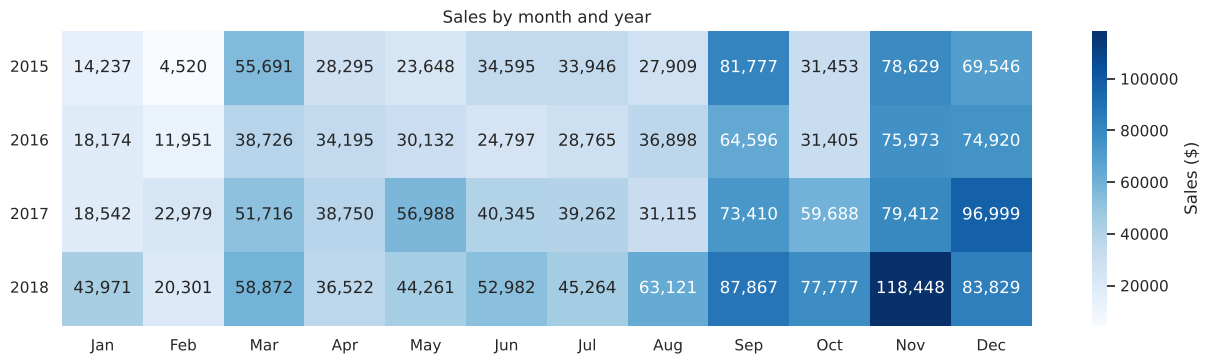

In [12]:
heat = orders.pivot_table(index="Year", columns="Month", values="Sales", aggfunc="sum")
heat.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(13, 3.8))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="Blues", cbar_kws={"label": "Sales ($)"})
plt.title("Sales by month and year")
plt.yticks(rotation=0)
plt.ylabel("")
plt.tight_layout()

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Avg % of annual sales,4.00,2.50,9.10,6.10,6.70,6.60,6.40,6.80,13.70,8.40,15.40,14.40


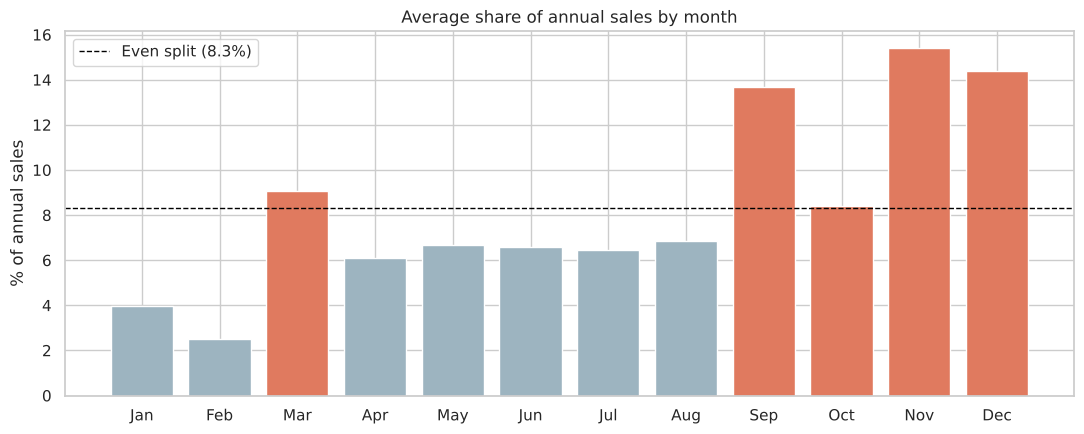

In [13]:
# Average share of annual sales that falls in each month (removes the growth trend)
share = heat.div(heat.sum(axis=1), axis=0) * 100
avg_share = share.mean().rename("Avg % of annual sales")

plt.figure(figsize=(11, 4.5))
colors = ["#E07A5F" if v > 100 / 12 else "#9DB4C0" for v in avg_share]
plt.bar(avg_share.index, avg_share.values, color=colors)
plt.axhline(100 / 12, color="black", linestyle="--", linewidth=1, label="Even split (8.3%)")
plt.title("Average share of annual sales by month")
plt.ylabel("% of annual sales")
plt.legend()
plt.tight_layout()
avg_share.round(1).to_frame().T

In [14]:
yearly = orders.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
yearly["Sales Growth %"] = yearly["Sales"].pct_change() * 100
yearly["Profit Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly

,Sales,Profit,Orders,Sales Growth %,Profit Margin %
Year,,,,,
2015,"484,247.50","49,543.97",969,NaN,10.23
2016,"470,532.51","61,618.60",1038,-2.83,13.10
2017,"609,205.60","81,795.17",1315,29.47,13.43
2018,"733,215.26","93,439.27",1687,20.36,12.74


## 4. Category, Region and Segment performance

In [15]:
def summarise(by):
    t = orders.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Quantity=("Quantity", "sum"))
    t["Margin %"] = t["Profit"] / t["Sales"] * 100
    return t.sort_values("Sales", ascending=False)

cat = summarise("Category")
cat

,Sales,Profit,Quantity,Margin %
Category,,,,
Technology,"836,154.03","145,454.95",6939,17.40
Furniture,"741,999.80","18,451.27",8028,2.49
Office Supplies,"719,047.03","122,490.80",22906,17.04


,Sales,Profit,Quantity,Margin %
Region,,,,
West,"725,457.82","108,418.45",12266,14.94
East,"678,781.24","91,522.78",10618,13.48
Central,"501,239.89","39,706.36",8780,7.92
South,"391,721.91","46,749.43",6209,11.93


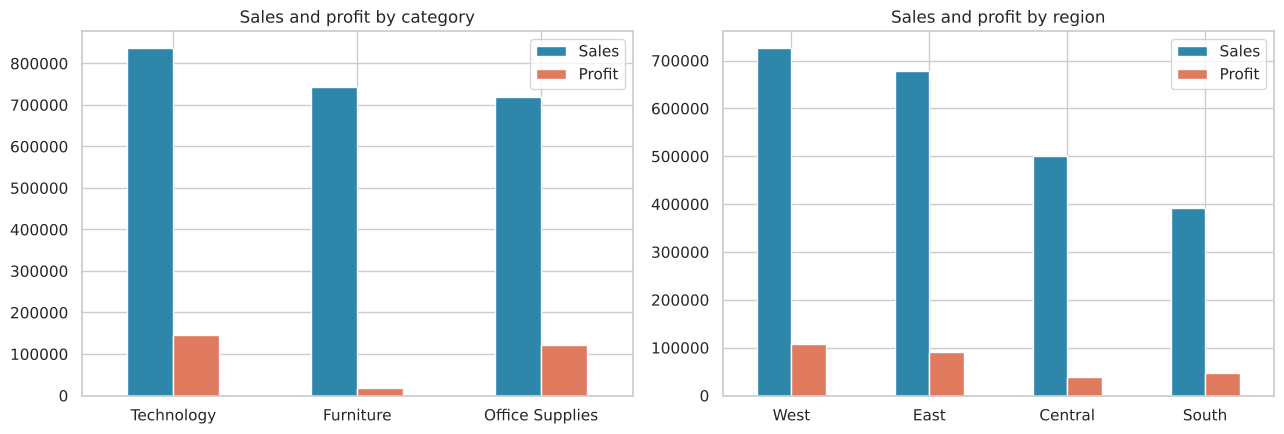

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cat[["Sales", "Profit"]].plot.bar(ax=ax[0], color=["#2E86AB", "#E07A5F"], rot=0)
ax[0].set_title("Sales and profit by category")
ax[0].set_xlabel("")
reg = summarise("Region")
reg[["Sales", "Profit"]].plot.bar(ax=ax[1], color=["#2E86AB", "#E07A5F"], rot=0)
ax[1].set_title("Sales and profit by region")
ax[1].set_xlabel("")
plt.tight_layout()
reg

,Sales,Profit,Quantity,Margin %
Sub-Category,,,,
Tables,"206,965.53","-17,725.48",1241,-8.56
Bookcases,"114,880.00","-3,472.56",868,-3.02
Supplies,"46,673.54","-1,189.10",647,-2.55
Fasteners,"3,024.28",949.52,914,31.40


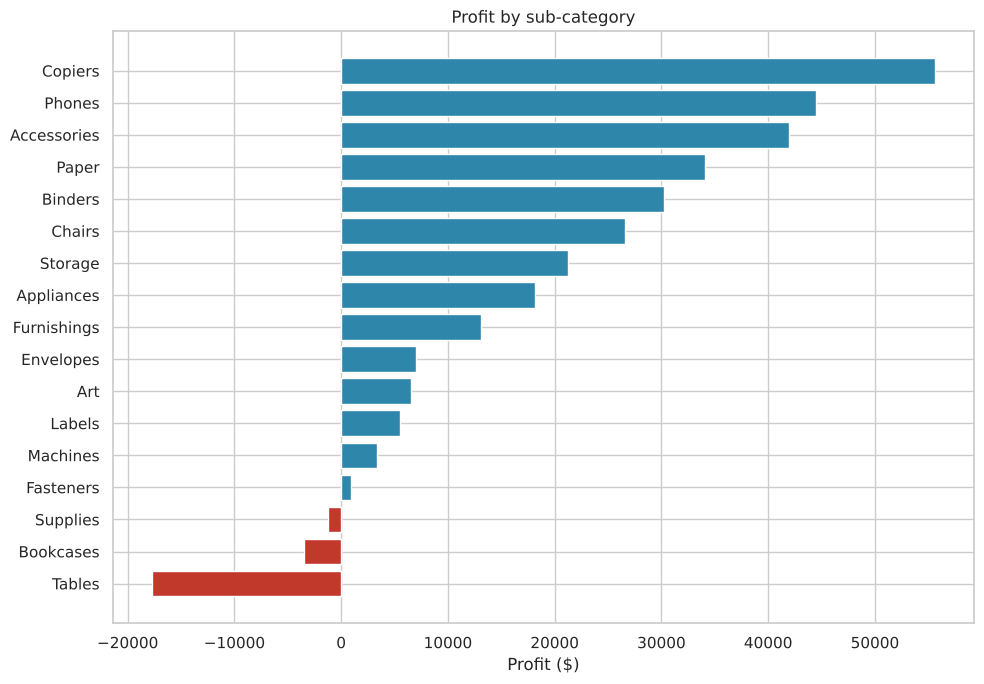

In [17]:
sub = summarise("Sub-Category").sort_values("Profit")

plt.figure(figsize=(10, 7))
colors = ["#C0392B" if v < 0 else "#2E86AB" for v in sub["Profit"]]
plt.barh(sub.index, sub["Profit"], color=colors)
plt.title("Profit by sub-category")
plt.xlabel("Profit ($)")
plt.tight_layout()
sub.sort_values("Profit").head(4)

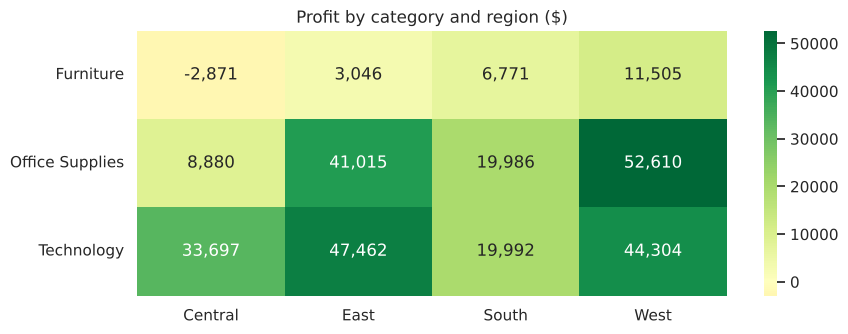

In [18]:
pivot = orders.pivot_table(index="Category", columns="Region", values="Profit", aggfunc="sum")
plt.figure(figsize=(9, 3.5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="RdYlGn", center=0)
plt.title("Profit by category and region ($)")
plt.yticks(rotation=0)
plt.ylabel("")
plt.xlabel("")
plt.tight_layout()

In [19]:
summarise("Segment")

,Sales,Profit,Quantity,Margin %
Segment,,,,
Consumer,"1,161,401.34","134,119.21",19521,11.55
Corporate,"706,146.37","91,979.13",11608,13.03
Home Office,"429,653.15","60,298.68",6744,14.03


In [20]:
# Worst states by profit
state = summarise("State").sort_values("Profit")
state.head(8)

,Sales,Profit,Quantity,Margin %
State,,,,
Texas,"170,188.05","-25,729.36",3724,-15.12
Ohio,"78,258.14","-16,971.38",1759,-21.69
Pennsylvania,"116,511.91","-15,559.96",2153,-13.35
Illinois,"80,166.10","-12,607.89",1845,-15.73
North Carolina,"55,603.16","-7,490.91",983,-13.47
Colorado,"32,108.12","-6,527.86",693,-20.33
Tennessee,"30,661.87","-5,341.69",681,-17.42
Arizona,"35,282.00","-3,427.92",862,-9.72


## 5. Discount sensitivity

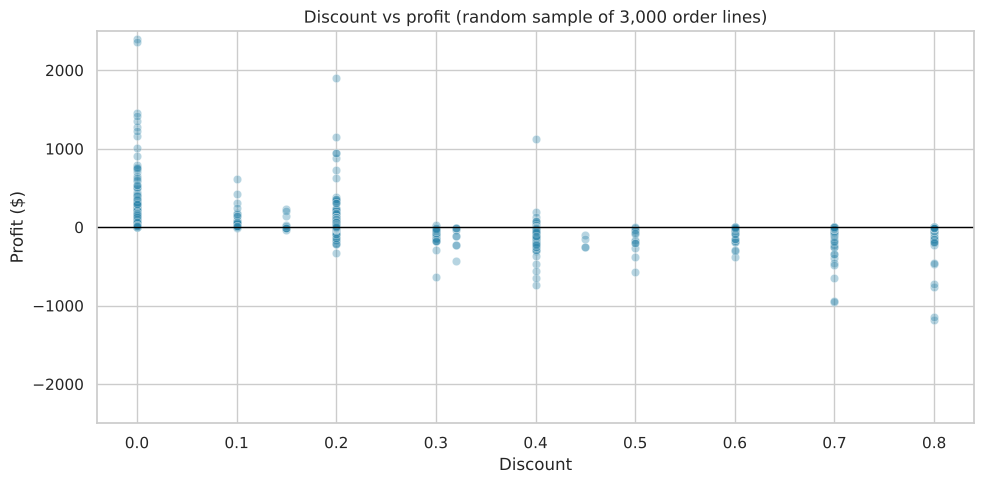

In [21]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=orders.sample(3000, random_state=1), x="Discount", y="Profit", alpha=0.35, color="#2E86AB")
plt.axhline(0, color="black", linewidth=1)
plt.ylim(-2500, 2500)
plt.title("Discount vs profit (random sample of 3,000 order lines)")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.tight_layout()

In [22]:
bins = [-0.001, 0, 0.2, 0.4, 1.0]
labels = ["No discount", "Up to 20%", "21% to 40%", "Above 40%"]
orders["Discount Band"] = pd.cut(orders["Discount"], bins=bins, labels=labels)

disc = orders.groupby("Discount Band", observed=True).agg(
    Lines=("Row ID", "count"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Profit_per_Line=("Profit", "mean"),
)
disc["Margin %"] = disc["Profit"] / disc["Sales"] * 100
disc["Share of Sales %"] = disc["Sales"] / disc["Sales"].sum() * 100
disc

,Lines,Sales,Profit,Avg_Profit_per_Line,Margin %,Share of Sales %
Discount Band,,,,,,
No discount,4798,"1,087,908.47","320,987.60",66.90,29.51,47.36
Up to 20%,3803,"846,522.24","100,785.47",26.50,11.91,36.85
21% to 40%,460,"234,137.90","-35,817.47",-77.86,-15.30,10.19
Above 40%,933,"128,632.25","-99,558.59",-106.71,-77.40,5.60


Correlation, discount vs profit margin: -0.86

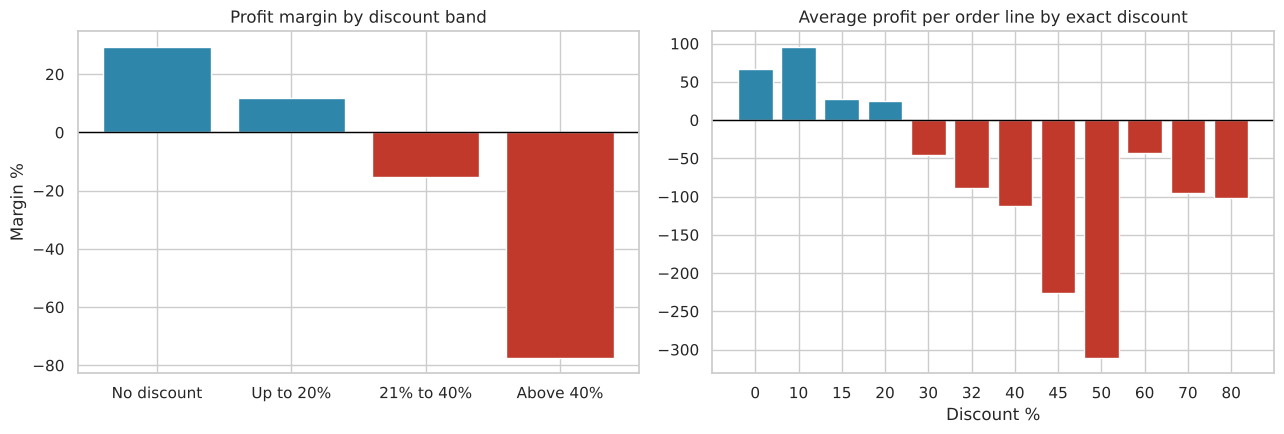

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
colors = ["#C0392B" if v < 0 else "#2E86AB" for v in disc["Margin %"]]
ax[0].bar(disc.index.astype(str), disc["Margin %"], color=colors)
ax[0].axhline(0, color="black", linewidth=1)
ax[0].set_title("Profit margin by discount band")
ax[0].set_ylabel("Margin %")

by_level = orders.groupby("Discount")["Profit"].mean()
ax[1].bar((by_level.index * 100).astype(int).astype(str), by_level.values,
          color=["#C0392B" if v < 0 else "#2E86AB" for v in by_level.values])
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_title("Average profit per order line by exact discount")
ax[1].set_xlabel("Discount %")
plt.tight_layout()

print("Correlation, discount vs profit margin:", round(orders["Discount"].corr(orders["Profit Margin %"]), 2))

In [24]:
# Where does the heavy discounting happen?
heavy = orders[orders["Discount"] > 0.3]
loss_from_heavy = heavy["Profit"].sum()
print(f"Order lines with discount above 30%: {len(heavy):,} ({len(heavy)/len(orders):.1%} of lines)")
print(f"Profit on those lines: ${loss_from_heavy:,.0f}")
print()
print(heavy.groupby("Category")["Profit"].sum().round(0))
print()
print(heavy.groupby("Region")["Profit"].sum().round(0))

Order lines with discount above 30%: 1,166 (11.7% of lines)
Profit on those lines: $-125,007

Category
Furniture         -43,782.00
Office Supplies   -47,140.00
Technology        -34,084.00
Name: Profit, dtype: float64

Region
Central   -45,851.00
East      -38,260.00
South     -24,880.00
West      -16,015.00
Name: Profit, dtype: float64

## 6. Returns

In [25]:
order_level = orders.groupby("Order ID").agg(Sales=("Sales", "sum"), Returned=("Returned", "first"))
ret_rate = (order_level["Returned"] == "Yes").mean()
ret_sales = order_level.loc[order_level["Returned"] == "Yes", "Sales"].sum() / order_level["Sales"].sum()
print(f"Return rate by order count: {ret_rate:.1%}")
print(f"Share of sales value returned: {ret_sales:.1%}")
orders.groupby("Category").apply(lambda g: g.loc[g["Returned"] == "Yes", "Order ID"].nunique() / g["Order ID"].nunique() * 100,
                                 include_groups=False).round(1).to_frame("Return rate % of orders")

Return rate by order count: 5.9%
Share of sales value returned: 7.9%

,Return rate % of orders
Category,
Furniture,7.70
Office Supplies,6.30
Technology,8.00


## 7. Key numbers behind the findings
These outputs back every number quoted in the findings below.

In [26]:
print("Sales growth 2015 to 2018:", f"{yearly['Sales'].iloc[-1] / yearly['Sales'].iloc[0] - 1:.0%}")
print("Q4 (Oct to Dec) share of annual sales:", f"{share.iloc[:, 9:12].sum(axis=1).mean():.1f}%")
print("Nov + Dec share:", f"{share.iloc[:, 10:12].sum(axis=1).mean():.1f}%")
print("Jan + Feb share:", f"{share.iloc[:, 0:2].sum(axis=1).mean():.1f}%")
print("Best months:", avg_share.sort_values(ascending=False).head(3).round(1).to_dict())
print("Weakest months:", avg_share.sort_values().head(3).round(1).to_dict())
print()
print(cat.round(1))
print(reg.round(1))
print(sub.round(1).head(4))
loss_subs = sub[sub["Profit"] < 0]
print("Loss-making sub-categories:", loss_subs.index.tolist(), "| combined loss:", round(loss_subs["Profit"].sum()))
print(disc.round(1).to_string())
over20 = orders[orders["Discount"] > 0.2]
print()
print(f"Discount above 20%: {len(over20)/len(orders):.1%} of lines, {over20['Sales'].sum()/total_sales:.1%} of sales, profit ${over20['Profit'].sum():,.0f}")
print(f"Furniture share of sales {cat.loc['Furniture','Sales']/total_sales:.1%}, of profit {cat.loc['Furniture','Profit']/total_profit:.1%}")
print("Average order value by year:", (orders.groupby('Year')['Sales'].sum() / orders.groupby('Year')['Order ID'].nunique()).round(0).to_dict())
print("Four worst states combined profit:", round(state.head(4)['Profit'].sum()))
print("Sean Miller loss by sub-category:")
print(orders[orders['Customer Name'] == 'Sean Miller'].groupby('Sub-Category')['Profit'].sum().sort_values().head(2).round(0))

Sales growth 2015 to 2018: 51%
Q4 (Oct to Dec) share of annual sales: 38.2%
Nov + Dec share: 29.8%
Jan + Feb share: 6.5%
Best months: {'Nov': 15.4, 'Dec': 14.4, 'Sep': 13.7}
Weakest months: {'Feb': 2.5, 'Jan': 4.0, 'Apr': 6.1}

                     Sales     Profit  Quantity  Margin %
Category                                                 
Technology      836,154.00 145,454.90      6939     17.40
Furniture       741,999.80  18,451.30      8028      2.50
Office Supplies 719,047.00 122,490.80     22906     17.00
             Sales     Profit  Quantity  Margin %
Region                                           
West    725,457.80 108,418.40     12266     14.90
East    678,781.20  91,522.80     10618     13.50
Central 501,239.90  39,706.40      8780      7.90
South   391,721.90  46,749.40      6209     11.90
                  Sales     Profit  Quantity  Margin %
Sub-Category                                          
Tables       206,965.50 -17,725.50      1241     -8.60
Bookcases    114,

## 8. Business findings

**1. Sales grew 51% from 2015 to 2018, but each order is getting smaller.**
Sales went from $484K to $733K and margin improved from 10.2% to 12.7%. After a flat 2016 (down 2.8%), growth came back in 2017 (up 29%) and 2018 (up 20%). Orders grew faster than sales (969 to 1,687), so the average order value fell from about $500 to $435. Growth is coming from more orders, not bigger baskets.

**2. Sales are strongly seasonal. Nov and Dec bring about 30% of the year.**
On average November (15.4%), December (14.4%) and September (13.7%) are the three biggest months. January and February together bring only 6.5%. Stock, staff and ad budget should be planned around September and Q4. The January and February slump is the best window for targeted offers, but not for deep discounts (see finding 4).

**3. Furniture sells like a star but earns almost nothing.**
Furniture is 32% of sales but only 6.4% of profit, with a 2.5% margin against about 17% for Technology and Office Supplies. Tables lose $17.7K (margin -8.6%) and Bookcases lose $3.5K. Fixing pricing and discounts on these two lines is the quickest way to lift total profit.

**4. Discounts above 20% destroy profit. This is the single biggest issue in the data.**
Lines with no discount earn a 29.5% margin and lines up to 20% earn 11.9%. Between 21% and 40% the margin turns negative (-15.3%) and above 40% it falls to -77.4%. The correlation between discount and margin is -0.86. Lines discounted above 20% are only 14% of all lines and 16% of sales, yet they lost $135K, which is nearly half of the $286K total profit. A discount cap of 20% (with manager approval above it) would protect margin.

**5. Central region and a few states drag results down.**
Central has a 7.9% margin against 14.9% for West, and heavy discounting there cost $45.9K. Texas, Ohio, Pennsylvania and Illinois together lost $70.9K, even though they bring real sales volume. These states are the first place to review discount rules and product mix.

**6. Customers come back, but repeat buying is not always profitable.**
98.5% of customers ordered more than once (6.3 orders on average), so retention is healthy. The top 20% of customers give 48% of sales. The top customer by sales, Sean Miller ($25K), actually produced a $1,981 loss, mostly from discounted Machines. Customer reviews should look at profit, not only revenue.

**7. About 6% of orders are returned (7.9% of sales value).**
Technology has the highest return rate (8.0%), followed by Furniture (7.7%). Returns are not the main profit problem, but they add cost to the categories that already have thin margins.

### Recommended actions
1. Cap discounts at 20% and require approval above that.
2. Reprice or drop discounting on Tables and Bookcases.
3. Plan inventory and campaigns around September and Q4.
4. Review Central region and the four loss-making states first.
5. Track customer profit, not only customer sales, when choosing key accounts.